[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/10_spectral_signatures_and_libraries.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🌈 Spectral Signatures, Sensor Concepts & Spectral Libraries
### Space Academy 2026 · Hyperspectral course · Week 1 — Introduction to hyperspectral EO / Spectral signatures, sensor concepts, and hyperspectral use cases (Lecture companion)

Every material reflects sunlight differently at each wavelength. Plotting reflectance against wavelength gives a
**spectral signature**. A hyperspectral sensor such as **Planet Tanager** samples that signature in ~420 narrow bands
from 380 to 2500 nm, finely enough to see individual **absorption features** caused by chlorophyll, water, clay minerals,
carbonates and more. This notebook accompanies the Week 1 lectures: it turns the concepts on the slides into plots
you can explore yourself.

**What you will learn**
- Why spectra look the way they do: the physics behind the main absorption features
- How to read, plot and compare spectra from a **spectral library**
- Sensor concepts: band centres, FWHM, spectral sampling vs spectral resolution, spatial resolution (GSD), mixed pixels and signal-to-noise ratio (SNR)
- What a multispectral sensor such as **Sentinel-2** loses compared with Tanager, measured with the **spectral angle**
- How to match a real image pixel to a library with the **Spectral Angle Mapper (SAM)**

**Prerequisites**: `00_EO_data_quickstart_notebook.ipynb` (STAC, HDF5, bands, indices). If you are not fluent with numpy arrays (axes, boolean masks, broadcasting), work through **`09_numpy_for_hyperspectral.ipynb`** first — it is 45–60 minutes and uses this same data.

**Data**
- The course reference library `data/spectral_library/tanager_reference_library.csv`: 19 median spectra of homogeneous areas
  in the course scenes, built by `tools/build_reference_library.py` using ESA WorldCover pure pixels plus simple spectral rules.
- Tanager scenes `20250223_165546_32_4001` (Usulután, El Salvador), `20250608_091605_90_4001` (Konya, Türkiye),
  `20241215_185916_33_4001` (Malibu, USA) and `20250219_053251_31_4001` (Korba, India). `hu.get_scene()` uses a local copy
  when one exists; otherwise it downloads the ~1 GB HDF5 from Planet's open STAC catalogue.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## 0. You already know multispectral — here is what changes

Most of you have worked with Sentinel-2 or Landsat for years. Almost everything you know still applies: reflectance
is reflectance, atmospheric correction is still atmospheric correction, and NDVI still means what it meant. This
table is the short version of what is genuinely different, and where in the course each difference is dealt with.

| With Sentinel-2 / Landsat | With Tanager / EnMAP | Where |
|---|---|---|
| 13 bands, chosen for you by the mission | 426 contiguous bands; **you** choose which to use | this notebook |
| You name bands by number (B4, B8) | You name them by **wavelength** — band numbers mean nothing across sensors | this notebook |
| Band maths: NDVI = (B8 − B4)/(B8 + B4) | Band maths still works, but the information is in the **shape and depth** of absorption features | §3, notebook 13 |
| L2A arrives ready to use | L2A **plus bad-band handling**: ~58 of 426 bands are unusable water-vapour channels you must remove yourself | notebook 11 |
| You trust the scene classification / cloud mask | The cloud mask flags bright desert as cloud — you must inspect it | notebook 11 |
| 10–20 m, wall-to-wall, ~5-day revisit | 30 m, narrow tasked swath — hyperspectral **complements** Sentinel-2, it does not replace it | §4 |
| A handful of features; any classifier copes | 350+ highly correlated bands **break** the classifiers you know (the Hughes phenomenon) | notebook 13, 15 |
| Spectral libraries are a curiosity | Libraries are central: you match image spectra against reference spectra | §2, notebook 14 |
| Mixed pixels are a nuisance | Mixed pixels are **quantifiable**: unmixing gives you sub-pixel fractions | notebook 14 |

**The one-sentence version:** multispectral tells you *how much* vegetation is in a pixel; hyperspectral can tell you
*which* material it is, and how much of the pixel it occupies.

**Skim where you can.** If you already know what reflectance, STAC and a COG are, skip the first half of
`00_EO_data_quickstart_notebook.ipynb` and start at its Tanager section. Nothing in this notebook assumes it.

In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

## 1. What shapes a spectrum?

**Surface reflectance** $\rho(\lambda)$ is the fraction of incoming sunlight that a surface reflects at wavelength
$\lambda$, from 0 (absorbs everything) to 1 (reflects everything). Three physical processes shape it:

| Process | Where | Example |
|---|---|---|
| **Electronic transitions**: photons excite electrons in pigments or metal ions | VIS–NIR (400–1100 nm) | chlorophyll absorbs blue and red light; Fe³⁺ in iron oxides absorbs near 900 nm |
| **Molecular vibrations** (overtones and combinations of O–H, C–H, Al–OH, CO₃ bonds) | SWIR (1100–2500 nm) | liquid water at 970/1200/1450/1940 nm; clays at 2200 nm; carbonates at 2340 nm |
| **Scattering** at internal interfaces | everywhere | the bright NIR plateau of leaves comes from scattering between cell walls and air spaces |

Absorption features are narrow, typically 10–50 nm wide. Detecting them needs **many narrow, contiguous bands**,
which is exactly what hyperspectral means.

Let's load the course library.

In [2]:
wl, lib, meta = hu.load_library()
p10 = pd.read_csv(hu.LIBRARY_DIR / "tanager_reference_library_p10.csv")
p90 = pd.read_csv(hu.LIBRARY_DIR / "tanager_reference_library_p90.csv")

print(f"{len(lib)} library spectra, {len(wl)} bands ({np.isfinite(lib['mangrove']).sum()} good bands)")
pd.DataFrame(meta)[["name", "place", "description", "n_pixels_used"]]

19 library spectra, 426 bands (354 good bands)


,name,place,description,n_pixels_used
0,mangrove,"Usulután, El Salvador","Dense mangrove forest, Jiquilisco Bay, El Salv...",400
1,tropical_tree_cover,"Usulután, El Salvador","Tropical tree cover inland of the mangroves, E...",400
2,sugarcane_cropland,"Usulután, El Salvador","Green cropland (mostly sugar cane), El Salvador",400
3,turbid_estuary_water,"Usulután, El Salvador","Sediment-rich estuary water, El Salvador",400
4,sand_beach,"Usulután, El Salvador","Bright sand beach / barrier island, El Salvador",89
5,irrigated_crop,"Konya, Türkiye","Irrigated, fully green crop field, Konya plain...",400
6,dry_bare_soil,"Konya, Türkiye","Bare, dry agricultural soil, Konya plain",400
7,dry_steppe_grassland,"Konya, Türkiye","Senescent steppe grassland, Konya",400
8,dense_urban,"Ho Chi Minh City, Vietnam","Dense built-up area, Ho Chi Minh City",400
9,bright_industrial_roof,"Ho Chi Minh City, Vietnam","Bright industrial roofs (warehouses), Ho Chi M...",400


Each entry is the **median** of up to 400 pure pixels (all nine 10 m WorldCover cells inside the 30 m Tanager pixel
agree). The 10th and 90th percentiles show the natural variability of each material. Bands removed during
preprocessing (water vapour, the noisy detector edges) are stored as `NaN`; `hu.plot_spectrum` breaks the line there.

## 2. The library, one material group at a time

The dotted lines mark the diagnostic features discussed above. The grey bands are the atmospheric windows where
there is no usable surface signal (see notebook 11).

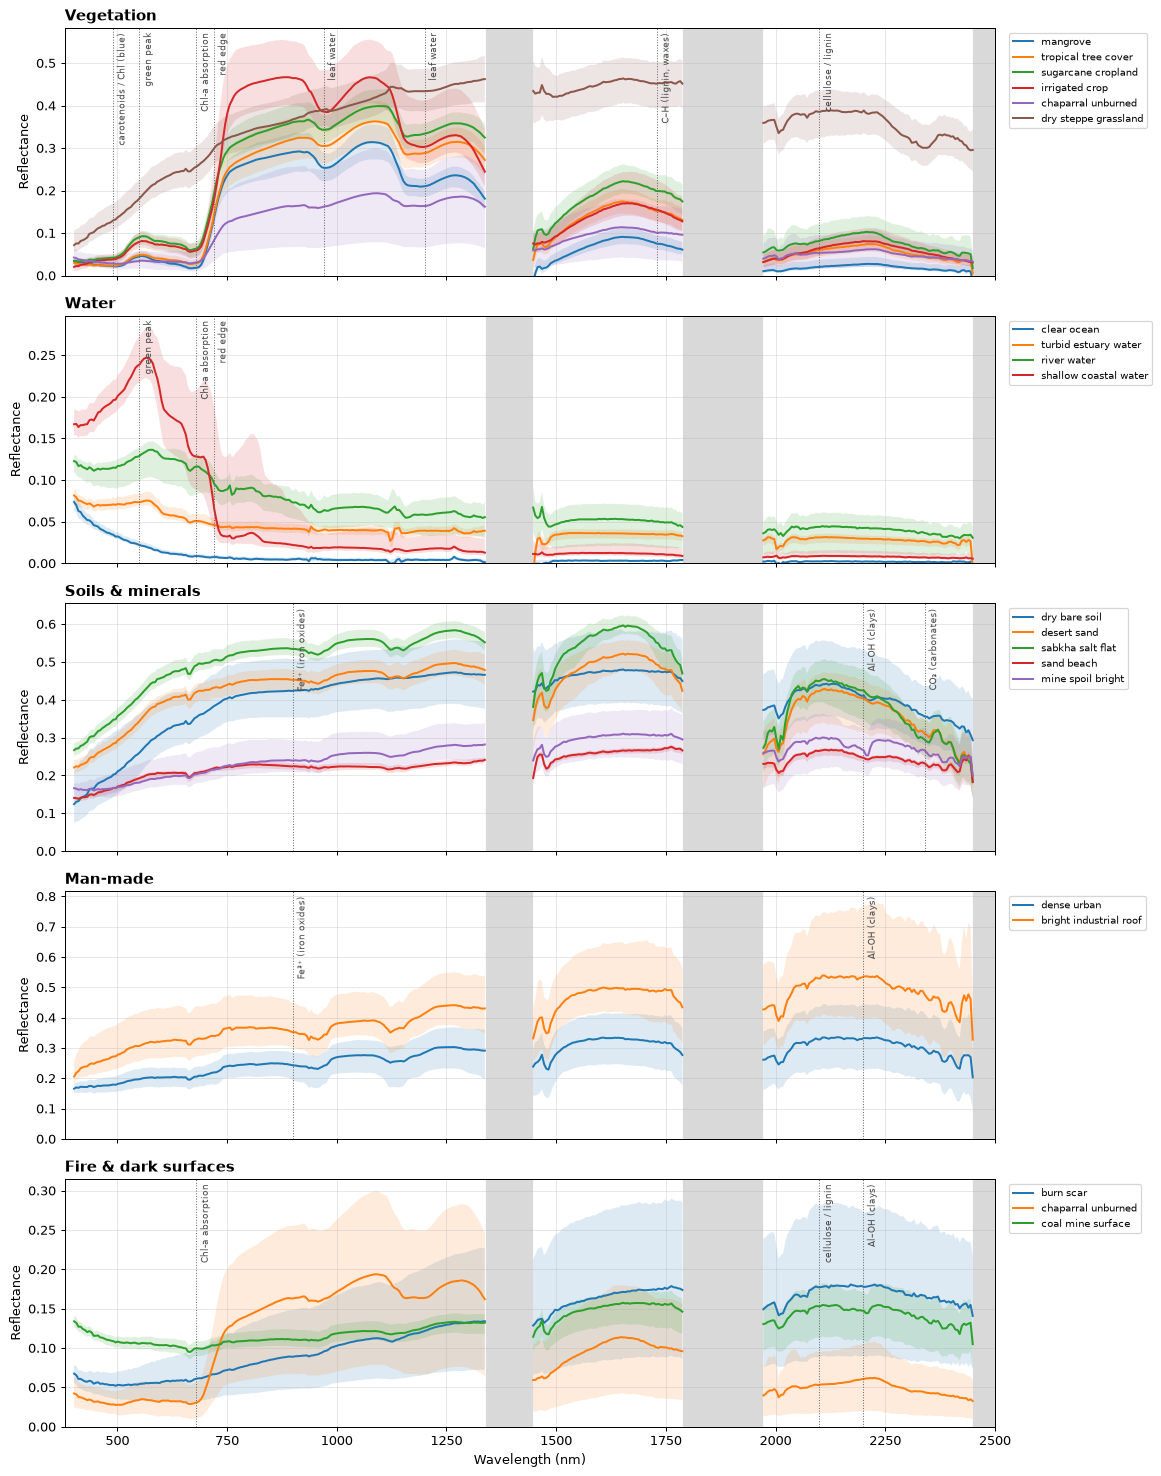

In [3]:
FEATURES = {  # wavelength (nm): label
    490: "carotenoids / Chl (blue)", 550: "green peak", 680: "Chl-a absorption", 720: "red edge",
    900: "Fe³⁺ (iron oxides)", 970: "leaf water", 1200: "leaf water", 1730: "C–H (lignin, waxes)",
    2100: "cellulose / lignin", 2200: "Al–OH (clays)", 2340: "CO₃ (carbonates)",
}

GROUPS = {
    "Vegetation": ["mangrove", "tropical_tree_cover", "sugarcane_cropland", "irrigated_crop",
                   "chaparral_unburned", "dry_steppe_grassland"],
    "Water": ["clear_ocean", "turbid_estuary_water", "river_water", "shallow_coastal_water"],
    "Soils & minerals": ["dry_bare_soil", "desert_sand", "sabkha_salt_flat", "sand_beach", "mine_spoil_bright"],
    "Man-made": ["dense_urban", "bright_industrial_roof"],
    "Fire & dark surfaces": ["burn_scar", "chaparral_unburned", "coal_mine_surface"],
}

def annotate_features(ax, which, ymax):
    for w in which:
        ax.axvline(w, color="0.4", ls=":", lw=0.8)
        ax.text(w + 8, ymax * 0.98, FEATURES[w], rotation=90, va="top", fontsize=7, color="0.3")

fig, axes = plt.subplots(len(GROUPS), 1, figsize=(13, 3.3 * len(GROUPS)), sharex=True)
feature_sets = {
    "Vegetation": [490, 550, 680, 720, 970, 1200, 1730, 2100],
    "Water": [550, 680, 720],
    "Soils & minerals": [900, 2200, 2340],
    "Man-made": [900, 2200],
    "Fire & dark surfaces": [680, 2100, 2200],
}
for ax, (group, names) in zip(axes, GROUPS.items()):
    hu.shade_bad_regions(ax)
    for n in names:
        line, = hu.plot_spectrum(ax, wl, lib[n], lw=1.6, label=n.replace("_", " "))
        ax.fill_between(wl, p10[n], p90[n], color=line.get_color(), alpha=0.15, lw=0)
    ymax = max(np.nanmax(p90[n]) for n in names) * 1.05
    ax.set_ylim(0, ymax)
    annotate_features(ax, feature_sets[group], ymax)
    ax.set_title(group, loc="left", fontweight="bold")
    ax.set_ylabel("Reflectance")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Wavelength (nm)")
axes[-1].set_xlim(380, 2500)
plt.tight_layout(); plt.show()

**What to look for**

- **Vegetation**: low blue and red (chlorophyll absorbs), a small green peak, then the steep **red edge** (690–740 nm)
  up to a bright NIR plateau. Liquid water in leaves causes the dips at 970 and 1200 nm and the low SWIR. The
  **dry steppe grassland** in Konya has almost lost its red edge and looks more like soil: senescent vegetation is
  dominated by cellulose and lignin, not chlorophyll.
- **Water** absorbs strongly beyond ~700 nm, so its NIR/SWIR reflectance should be near zero, as it is for the clear
  ocean. Suspended sediment raises the green–red signal (turbid estuary, river), and a bright sandy bottom raises the
  blue–green signal of the **shallow coastal water** in the UAE. The estuary and river spectra keep 0.02–0.05 reflectance
  in the SWIR, which pure water cannot have. This comes from sun glint, adjacency effects (light scattered from bright
  land nearby) and atmospheric-correction residuals. Water-quality work therefore often subtracts a SWIR baseline (theme notebook 06).
- **Soils and minerals** are bright and relatively smooth. The steep rise from blue to red in soils is caused by
  **iron oxides** (strong charge-transfer absorption in the blue); their weaker band near 900 nm is subtle in these
  spectra. Other diagnostic information sits in *small* SWIR dips: look for the Al–OH clay feature near 2200 nm in the
  Korba **mine spoil** and the carbonate feature near 2340 nm in the UAE **sabkha** and **desert sand**.
- **Man-made** surfaces are materials too: concrete, metal and painted roofs have their own shapes, so urban mapping
  can go beyond a single "built-up" class (notebook 14).
- **Fire**: the **burn scar** has lost its red edge and leaf-water features. Its reflectance rises steadily into the SWIR
  (char plus ash, no leaf water); compare it with the unburned chaparral next to it. The **coal mine surface** is dark
  and flat.
- The bands of variability (p10–p90) are wide: a material is a *distribution* of spectra, not a single line.

## 3. Zooming into absorption features: continuum removal

Small features are hard to see on a sloping, bright spectrum. **Continuum removal** divides the spectrum by its upper
convex hull (the *continuum*), so every feature becomes a dip below 1.0 and its **band depth**
$D = 1 - \rho_{\text{feature}}/\rho_{\text{continuum}}$ can be compared between bright and dark materials
(Clark & Roush, 1984).

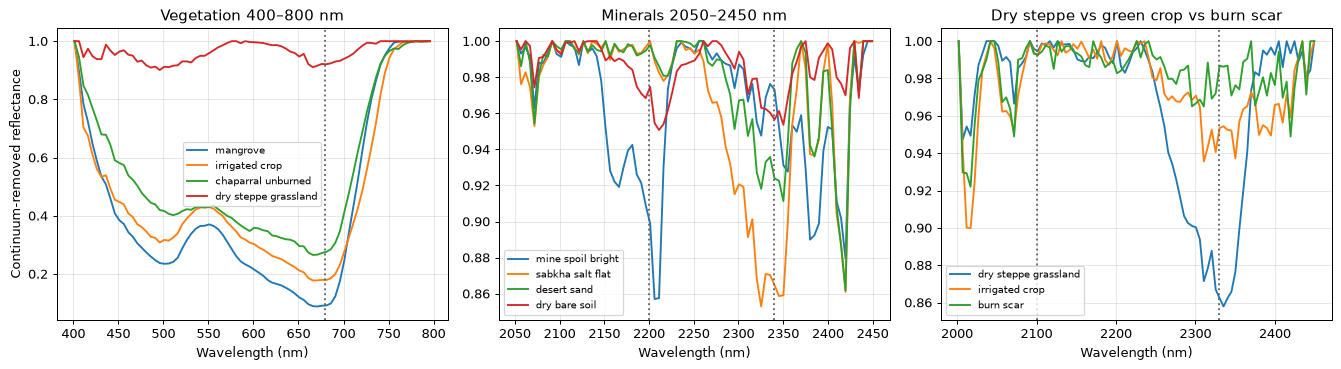

,Chl 680,Al–OH 2200,CO₃ 2340
mine_spoil_bright,0.030,0.094,-0.001
sand_beach,0.024,0.044,0.024
clear_ocean,0.298,0.039,0.075
coal_mine_surface,0.074,0.030,0.017
dry_bare_soil,-0.003,0.018,0.038
turbid_estuary_water,0.072,0.005,0.022
river_water,-0.111,-0.002,0.014
desert_sand,-0.034,-0.010,0.049
burn_scar,0.078,-0.011,-0.009
dense_urban,0.083,-0.020,0.005


In [4]:
def cr_segment(name, lo, hi):
    m = (wl >= lo) & (wl <= hi) & np.isfinite(lib[name])
    return wl[m], hu.continuum_removed(wl[m], lib[name][m])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
panels = [
    ("Vegetation 400–800 nm", 400, 800, ["mangrove", "irrigated_crop", "chaparral_unburned", "dry_steppe_grassland"], [680]),
    ("Minerals 2050–2450 nm", 2050, 2450, ["mine_spoil_bright", "sabkha_salt_flat", "desert_sand", "dry_bare_soil"], [2200, 2340]),
    ("Dry steppe vs green crop vs burn scar", 2000, 2450, ["dry_steppe_grassland", "irrigated_crop", "burn_scar"], [2100, 2330]),
]
for ax, (title, lo, hi, names, marks) in zip(axes, panels):
    for n in names:
        x, y = cr_segment(n, lo, hi)
        ax.plot(x, y, lw=1.5, label=n.replace("_", " "))
    for w in marks:
        ax.axvline(w, color="0.4", ls=":")
    ax.set_title(title); ax.set_xlabel("Wavelength (nm)"); ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Continuum-removed reflectance")
plt.tight_layout(); plt.show()

depths = {n: {"Chl 680": hu.band_depth(wl, lib[n], 550, 675, 750),
              "Al–OH 2200": hu.band_depth(wl, lib[n], 2120, 2200, 2260),
              "CO₃ 2340": hu.band_depth(wl, lib[n], 2280, 2340, 2400)} for n in lib}
pd.DataFrame(depths).T.round(3).sort_values("Al–OH 2200", ascending=False)

The table ranks the library by the depth of each feature (negative values mean there is no dip).

- The **chlorophyll** dip is deep (0.7–0.9) for green vegetation and nearly absent for dry grass, burn scar and bare soil.
- The **Al–OH** feature is clearest in the **Korba mine spoil**. The middle panel shows a *doublet* near 2165 and
  2205 nm, the classic shape of **kaolinite**, which fits the kaolinite-bearing sandstones and shales dug up in the
  open-cast coal mines. Green vegetation gets a *negative* value in this column because its SWIR slope is convex, not
  because it contains clay.
- The **carbonate** feature (~2330–2340 nm) appears in the UAE **sabkha** and **desert sand** (carbonate-rich coastal sediments).
- The **dry steppe** has a broad absorption centred near 2330 nm. It combines cellulose/lignin absorption of dead plant
  material with carbonate in the calcareous Konya soils. The classic ~2100 nm cellulose feature is weak here because the
  sparse dry grass is mixed with soil at 30 m. Expect this with real image spectra.
- Sharp dips that appear at the **same wavelength in every spectrum**, near **2010 and 2060 nm** (CO₂) and just above
  1450 nm (water vapour), are **atmospheric residuals** left over after atmospheric correction, not surface properties.
  Notebook 11 shows how to spot them.

> ⚠️ Image-derived spectra are always somewhat **mixed** (30 m pixels) and carry atmospheric residuals. For mineral
> identification, compare them with laboratory spectra (section 8) and interpret feature *positions* and *shapes*, not only depths.

## 4. Sensor concepts

### 4.1 Band centres, spectral sampling and spectral resolution

- **Band centre**: the wavelength a band is centred on.
- **Spectral sampling**: the distance between neighbouring band centres (~5 nm for Tanager).
- **Spectral resolution (FWHM)**: the *width* of each band's response, measured as the Full Width at Half Maximum.

Sampling and resolution are different things: a sensor can have bands every 5 nm that are each 10 nm wide (they overlap).
Tanager's FWHM is close to its sampling interval, so neighbouring bands barely overlap.

Scene      : 20250608_091605_90_4001  (Konya, Türkiye)
File       : /home/course/notebooks/20250608_091605_90_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 673 rows × 776 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32636, 30 m pixels
No-data    : 30.4%   cloud flag: 1.2%   cirrus flag: 0.0%   usable: 68.4%


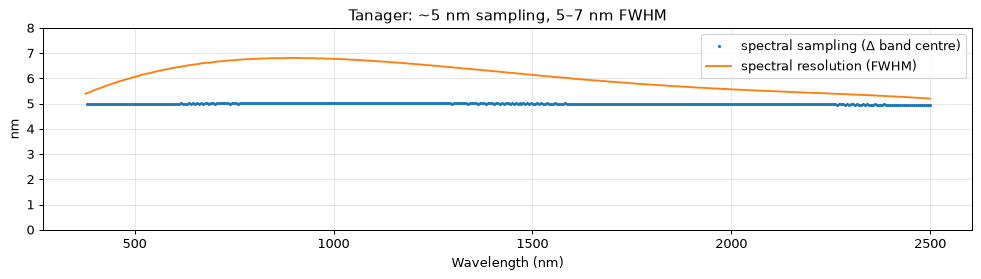

In [5]:
scene = hu.get_scene("20250608_091605_90_4001")   # Konya, Türkiye
print(scene.summary())

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(scene.wavelengths[1:], np.diff(scene.wavelengths), ".", ms=3, label="spectral sampling (Δ band centre)")
ax.plot(scene.wavelengths, scene.fwhm, "-", lw=1.5, label="spectral resolution (FWHM)")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("nm"); ax.set_ylim(0, 8)
ax.set_title("Tanager: ~5 nm sampling, 5–7 nm FWHM"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 4.2 Spectral response functions: Tanager vs EnMAP vs Sentinel-2 vs Landsat

Each band integrates the incoming signal over its **spectral response function (SRF)**. Here every SRF is approximated
by a Gaussian with the band's centre and FWHM, which is accurate enough to compare sensors. Sentinel-2 and Landsat
values come from the published band tables; the EnMAP grid is a nominal approximation. A mangrove spectrum is drawn in
grey for orientation.

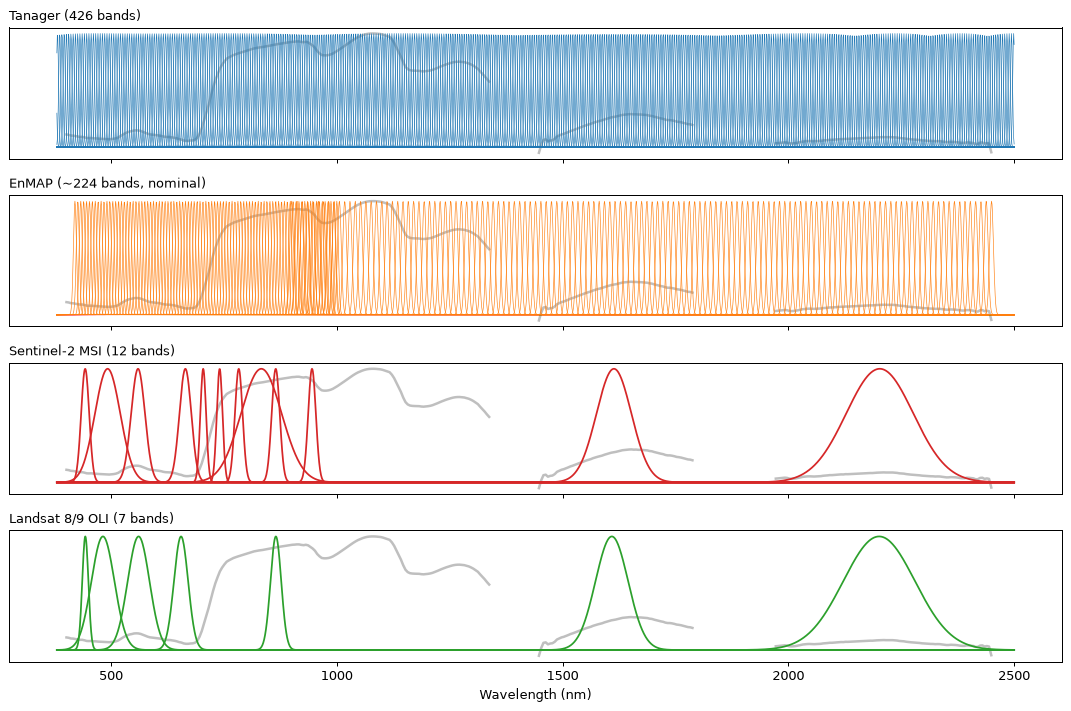

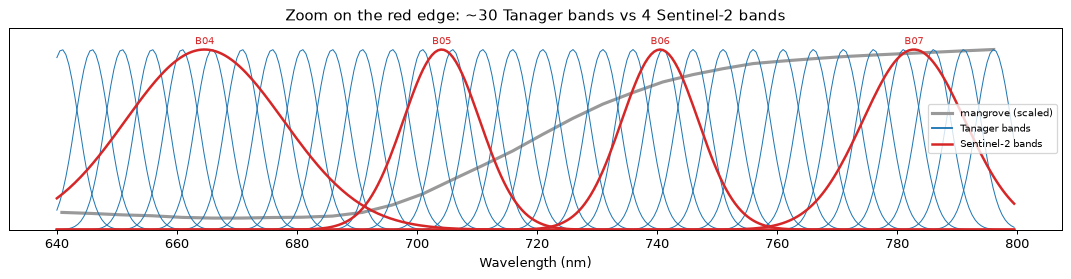

In [6]:
def gaussian(x, c, fwhm):
    s = fwhm / (2 * np.sqrt(2 * np.log(2)))
    return np.exp(-0.5 * ((x - c) / s) ** 2)

x = np.arange(380, 2501, 1.0)
sensors = {
    f"Tanager ({len(scene.wavelengths)} bands)": (scene.wavelengths, scene.fwhm),
    f"EnMAP (~{len(hu.ENMAP_APPROX['centers'])} bands, nominal)": (hu.ENMAP_APPROX["centers"], hu.ENMAP_APPROX["fwhm"]),
    f"Sentinel-2 MSI ({len(hu.SENTINEL2_BANDS)} bands)": tuple(np.array(list(hu.SENTINEL2_BANDS.values())).T),
    f"Landsat 8/9 OLI ({len(hu.LANDSAT8_BANDS)} bands)": tuple(np.array(list(hu.LANDSAT8_BANDS.values())).T),
}
colors = ["C0", "C1", "C3", "C2"]
fig, axes = plt.subplots(len(sensors), 1, figsize=(12, 8), sharex=True)
for ax, col, (name, (cen, fw)) in zip(axes, colors, sensors.items()):
    ax.plot(wl, lib["mangrove"] / np.nanmax(lib["mangrove"]), color="0.75", lw=2, zorder=0)
    for c, f in zip(cen, fw):
        ax.plot(x, gaussian(x, c, f), color=col, lw=0.5 if len(cen) > 50 else 1.4)
    ax.set_title(name, loc="left", fontsize=10); ax.set_yticks([])
axes[-1].set_xlabel("Wavelength (nm)")
plt.tight_layout(); plt.show()

# Zoom into the red edge, where vegetation information is densest
xz = np.arange(640, 800, 0.5)
fig, ax = plt.subplots(figsize=(12, 3.2))
m = (wl > 640) & (wl < 800)
ax.plot(wl[m], lib["mangrove"][m] / np.nanmax(lib["mangrove"][m]), color="0.6", lw=2.5, label="mangrove (scaled)")
for c, f in zip(scene.wavelengths, scene.fwhm):
    if 640 < c < 800:
        ax.plot(xz, gaussian(xz, c, f), color="C0", lw=0.8)
for b in ["B04", "B05", "B06", "B07"]:
    c, f = hu.SENTINEL2_BANDS[b]
    ax.plot(xz, gaussian(xz, c, f), color="C3", lw=2)
    ax.text(c, 1.03, b, color="C3", ha="center", fontsize=8)
ax.plot([], [], color="C0", label="Tanager bands"); ax.plot([], [], color="C3", lw=2, label="Sentinel-2 bands")
ax.set_ylim(0, 1.12); ax.set_xlabel("Wavelength (nm)"); ax.set_yticks([]); ax.legend(loc="center right", fontsize=8)
ax.set_title("Zoom on the red edge: ~30 Tanager bands vs 4 Sentinel-2 bands")
plt.tight_layout(); plt.show()

The multispectral sensors have **gaps** (nothing measured between bands) and **wide bands** (Sentinel-2 B12 is
175 nm wide and swallows the whole 2100–2300 nm region). That is why a single Sentinel-2 value cannot separate the clay,
carbonate and cellulose features. Tanager covers the spectrum contiguously.

### 4.3 Spatial resolution and mixed pixels

Tanager's ground sampling distance (GSD) is about **30 m**, so one pixel covers 900 m². Most pixels therefore contain
several materials. The simplest description is the **linear mixing model**: the pixel spectrum is the area-weighted sum
of the pure spectra (*endmembers*),

$$\rho_{\text{pixel}}(\lambda) = \sum_i f_i\,\rho_i(\lambda), \qquad f_i \ge 0,\ \sum_i f_i = 1 .$$

Below we look at a real pixel on the bank of a mangrove creek in El Salvador. We take the two endmembers from the
same image (the greenest mangrove pixels and the darkest creek water) and estimate the pixel's fractions by
non-negative least squares with a sum-to-one constraint. Notebook 14 treats spectral unmixing properly.

Pixel NDVI = 0.44
Estimated fractions: mangrove 0.09, water 0.91  (model RMSE 0.0032)


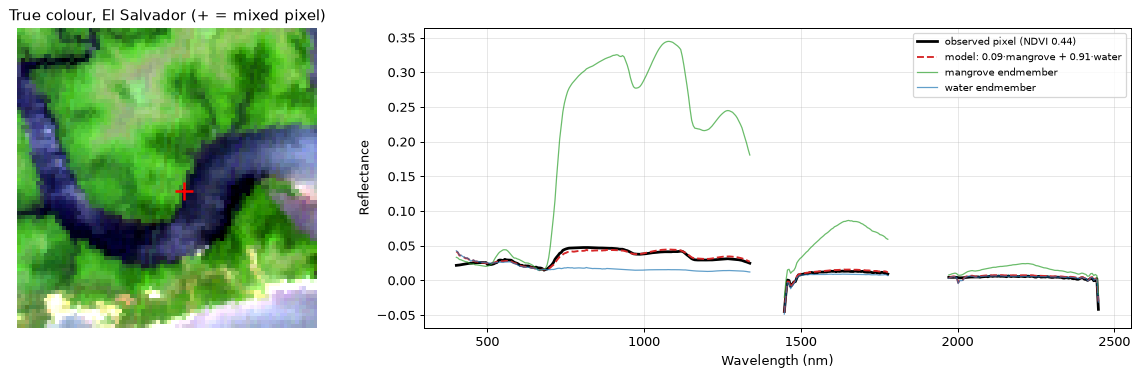

In [7]:
from scipy.optimize import nnls

es = hu.get_scene("20250223_165546_32_4001")     # Usulután, El Salvador
row0, col0 = es.lonlat_to_rowcol(-88.4652, 13.2215)   # inside the mangroves
win = (int(row0[0]) - 40, int(row0[0]) + 40, int(col0[0]) - 40, int(col0[0]) + 40)
cube, wl_es = es.read_cube(win)
nir, red = cube[hu.band_index(wl_es, 860)], cube[hu.band_index(wl_es, 665)]
ndvi = hu.nd(nir, red)

# image endmembers: median of the 5 % greenest pixels and of the 5 % darkest (NIR) water pixels
veg_em = np.nanmedian(cube[:, ndvi > np.nanpercentile(ndvi, 95)], axis=1)
wat_em = np.nanmedian(cube[:, nir < np.nanpercentile(nir, 5)], axis=1)
E = np.stack([veg_em, wat_em], axis=1)
ok = np.all(np.isfinite(E), axis=1)

# a creek-bank pixel: NDVI between 0.35 and 0.45, the one closest to the window centre
rr, cc = np.nonzero((ndvi > 0.35) & (ndvi < 0.45))
k = np.argmin((rr - 40) ** 2 + (cc - 40) ** 2)
r, c = rr[k], cc[k]
pix = cube[:, r, c]

# sum-to-one constraint: append a heavily weighted row of ones (a common trick, see notebook 14)
delta = 10.0
f, _ = nnls(np.vstack([E[ok], delta * np.ones((1, 2))]), np.append(pix[ok], delta))
rmse = np.sqrt(np.mean((E[ok] @ f - pix[ok]) ** 2))
print(f"Pixel NDVI = {ndvi[r, c]:.2f}")
print(f"Estimated fractions: mangrove {f[0]:.2f}, water {f[1]:.2f}  (model RMSE {rmse:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 2]})
axes[0].imshow(hu.rgb_from_cube(cube, wl_es)); axes[0].plot(c, r, "r+", ms=14, mew=2)
axes[0].set_title("True colour, El Salvador (+ = mixed pixel)"); axes[0].axis("off")
hu.plot_spectrum(axes[1], wl_es, pix, lw=2.2, color="k", label=f"observed pixel (NDVI {ndvi[r, c]:.2f})")
hu.plot_spectrum(axes[1], wl_es, E @ f, lw=1.5, ls="--", color="C3", label=f"model: {f[0]:.2f}·mangrove + {f[1]:.2f}·water")
hu.plot_spectrum(axes[1], wl_es, E[:, 0], lw=1, color="C2", alpha=0.7, label="mangrove endmember")
hu.plot_spectrum(axes[1], wl_es, E[:, 1], lw=1, color="C0", alpha=0.7, label="water endmember")
axes[1].set_xlabel("Wavelength (nm)"); axes[1].set_ylabel("Reflectance"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

The two-endmember model reproduces the pixel almost perfectly, and it reveals something surprising: a pixel with
**NDVI ≈ 0.44**, which many people would call "moderately vegetated", contains only **about 10 % mangrove**. Water is so
dark in the red and NIR that a small vegetated fraction dominates the ratio. NDVI is **not linear in vegetation
cover**, a good reason to prefer fractions from unmixing when you need area estimates, for example of blue carbon.

### 4.4 Signal-to-noise ratio (SNR) per band

SNR depends on

- the **sensor** (detector sensitivity, band width, integration time),
- the **atmosphere** (little light reaches the sensor in absorption bands), and
- the **target**: dark water returns far fewer photons than bright soil.

Tanager files contain a per-pixel, per-band **`surface_reflectance_uncertainty`** estimate. Dividing reflectance by that
uncertainty gives one SNR estimate. A second, independent estimate comes from the **image itself**: over a *homogeneous*
area, differences between neighbouring pixels are mostly noise. The robust standard deviation of those differences,
divided by √2, estimates the per-pixel noise. We compare both over bright fields in Konya and over homogeneous open
ocean off Malibu.

/var/folders/p7/35h46x0n4b90j_xp1kkvrrnm0000gn/T/ipykernel_39899/3165820477.py:12: RuntimeWarning: divide by zero encountered in divide
  return w, np.nanmedian(refl, axis=(1, 2)) / noise


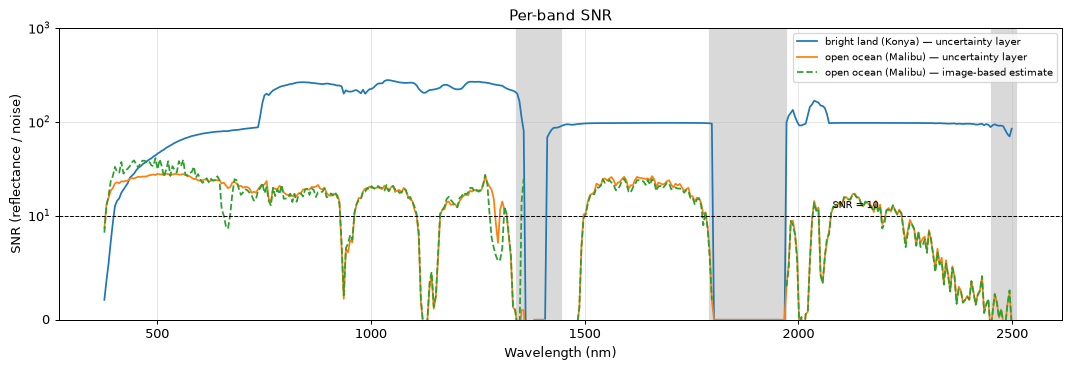

In [8]:
def snr_uncertainty(sc, window):
    refl, w = sc.read_cube(window, bands="all")
    unc, _ = sc.read_cube(window, bands="all", dataset="surface_reflectance_uncertainty")
    return w, np.nanmedian((refl / unc).reshape(len(w), -1), axis=1)

def snr_image(sc, window):
    # robust shift-difference noise estimate: MAD of horizontal neighbour differences / sqrt(2)
    refl, w = sc.read_cube(window, bands="all")
    d = refl[:, :, 1:] - refl[:, :, :-1]
    mad = np.nanmedian(np.abs(d - np.nanmedian(d, axis=(1, 2), keepdims=True)), axis=(1, 2))
    noise = 1.4826 * mad / np.sqrt(2)
    return w, np.nanmedian(refl, axis=(1, 2)) / noise

malibu = hu.get_scene("20241215_185916_33_4001")
land_win, water_win = (250, 330, 350, 430), (600, 660, 350, 450)
w1, snr_land_u = snr_uncertainty(scene, land_win)
w2, snr_water_u = snr_uncertainty(malibu, water_win)
w3, snr_water_i = snr_image(malibu, water_win)

fig, ax = plt.subplots(figsize=(12, 4.2))
hu.shade_bad_regions(ax)
ax.plot(w1, snr_land_u, lw=1.4, label="bright land (Konya) — uncertainty layer")
ax.plot(w2, snr_water_u, lw=1.4, label="open ocean (Malibu) — uncertainty layer")
ax.plot(w3, snr_water_i, lw=1.4, ls="--", label="open ocean (Malibu) — image-based estimate")
ax.set_yscale("symlog", linthresh=10); ax.set_ylim(0, 1000)
ax.axhline(10, color="k", ls="--", lw=0.8); ax.text(2080, 12, "SNR = 10", fontsize=8)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("SNR (reflectance / noise)")
ax.set_title("Per-band SNR"); ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Three lessons:

1. **The spectral regions to drop.** The SNR collapses in the atmospheric water-vapour windows (grey) and below ~400 nm,
   which is why the course removes those bands by default (`hu.good_band_mask`, `hu.MIN_WL_NM`).
2. **Bright land has excellent SNR**, around 100–250 across most of the spectrum.
3. **Dark water has an SNR of only ~10–25** in the NIR and SWIR, because water leaves almost no signal there. The two
   independent estimates agree over this homogeneous ocean, so the uncertainty layer is a sensible per-pixel noise
   estimate. Treat NIR/SWIR band ratios over clear water with suspicion. Notebook 11 shows where the image-based
   estimate goes wrong (textured areas).

## 5. What does Sentinel-2 see? Resampling the library

We can **simulate** a multispectral sensor by convolving each hyperspectral spectrum with that sensor's band responses
(`hu.resample_to_sensor`). This is the same operation used to harmonise Tanager with Sentinel-2 or EnMAP (notebook 30).

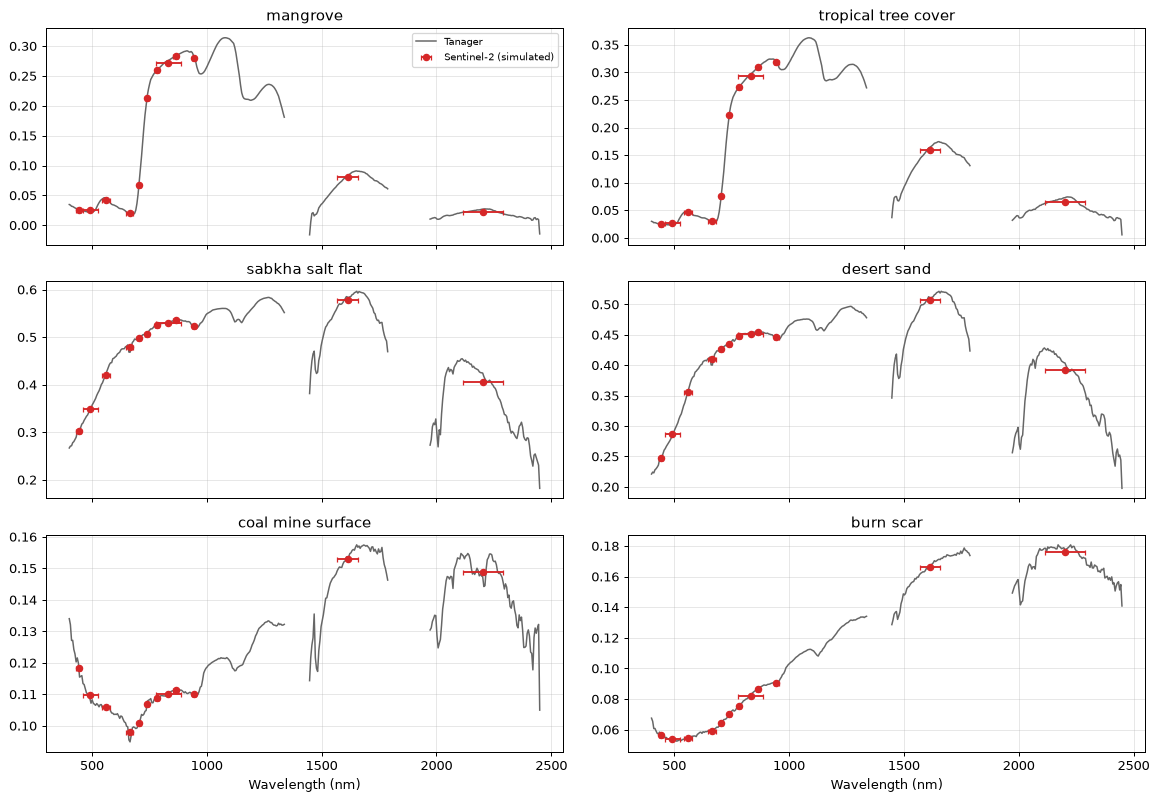

In [9]:
s2_names = list(hu.SENTINEL2_BANDS)
s2_c = np.array([v[0] for v in hu.SENTINEL2_BANDS.values()])
s2_w = np.array([v[1] for v in hu.SENTINEL2_BANDS.values()])
names = list(lib)
L = np.array([lib[n] for n in names])                   # (19, bands), NaN in removed bands
L_s2 = hu.resample_to_sensor(wl, L, s2_c, s2_w)         # (19, 12)

show = ["mangrove", "tropical_tree_cover", "sabkha_salt_flat", "desert_sand", "coal_mine_surface", "burn_scar"]
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for ax, n in zip(axes.flat, show):
    i = names.index(n)
    hu.plot_spectrum(ax, wl, L[i], color="0.4", lw=1.2, label="Tanager")
    ax.errorbar(s2_c, L_s2[i], xerr=s2_w / 2, fmt="o", color="C3", ms=5, capsize=2, label="Sentinel-2 (simulated)")
    ax.set_title(n.replace("_", " ")); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Wavelength (nm)")
plt.tight_layout(); plt.show()

The simulated Sentinel-2 points follow the general shape but miss the details: the exact red-edge shape, the leaf-water
dips, and all SWIR mineral features, which fall inside the wide B11/B12 bands or between bands.

### 5.1 Spectral separability with the spectral angle

The **spectral angle** between two spectra $\mathbf{a}$ and $\mathbf{b}$ treats them as vectors in *n*-dimensional band space:

$$\theta = \arccos\frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

It depends only on spectral **shape**, not on brightness, so shading and topography have little effect (Kruse et al., 1993).
A larger angle means the materials are easier to tell apart. We compute it for every pair of library spectra at
Tanager resolution (good bands only) and at simulated Sentinel-2 resolution.

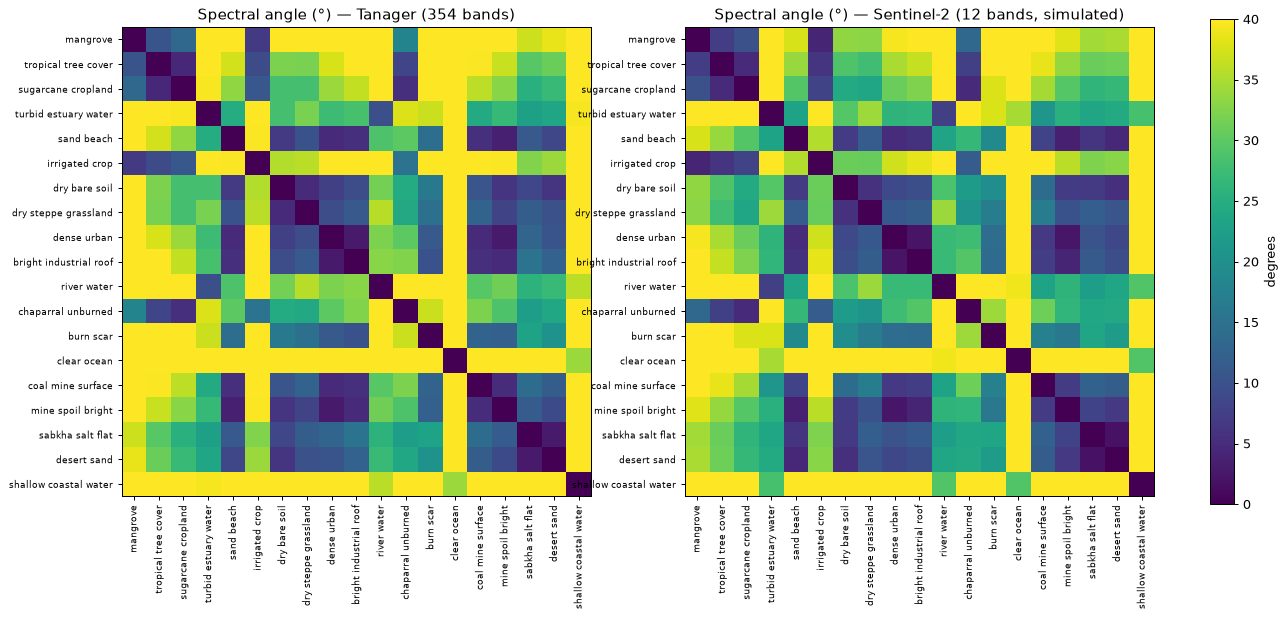

All 171 pairs: 71 % become less separable with Sentinel-2; median angle retained 91 %


,pair,tanager_deg,sentinel2_deg,retained
0,mangrove vs tropical_tree_cover,10.44,7.24,69 %
1,irrigated_crop vs sugarcane_cropland,10.85,8.23,76 %
2,sabkha_salt_flat vs desert_sand,2.91,1.97,68 %
3,coal_mine_surface vs burn_scar,12.69,17.35,137 %
4,dense_urban vs mine_spoil_bright,2.83,2.49,88 %
5,dry_bare_soil vs dry_steppe_grassland,4.79,5.72,119 %


In [10]:
def sam_matrix(S):
    S = S / np.linalg.norm(S, axis=1, keepdims=True)
    return np.degrees(np.arccos(np.clip(S @ S.T, -1, 1)))

good = np.all(np.isfinite(L), axis=0)
A_tan = sam_matrix(L[:, good])
A_s2 = sam_matrix(L_s2)

labels = [n.replace("_", " ") for n in names]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, A, title in [(axes[0], A_tan, f"Tanager ({good.sum()} bands)"), (axes[1], A_s2, "Sentinel-2 (12 bands, simulated)")]:
    im = ax.imshow(A, cmap="viridis", vmin=0, vmax=40)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(labels, fontsize=7)
    ax.set_title(f"Spectral angle (°) — {title}")
plt.colorbar(im, ax=axes, fraction=0.025, label="degrees")
plt.show()

pairs = [("mangrove", "tropical_tree_cover"), ("irrigated_crop", "sugarcane_cropland"),
         ("sabkha_salt_flat", "desert_sand"), ("coal_mine_surface", "burn_scar"),
         ("dense_urban", "mine_spoil_bright"), ("dry_bare_soil", "dry_steppe_grassland")]
rows = []
for a, b in pairs:
    i, j = names.index(a), names.index(b)
    rows.append(dict(pair=f"{a} vs {b}", tanager_deg=A_tan[i, j], sentinel2_deg=A_s2[i, j],
                     retained=f"{A_s2[i, j] / A_tan[i, j] * 100:.0f} %"))

iu = np.triu_indices(len(names), 1)
ratio = A_s2[iu] / A_tan[iu]
print(f"All {len(ratio)} pairs: {np.mean(ratio < 1) * 100:.0f} % become less separable with Sentinel-2; "
      f"median angle retained {np.median(ratio) * 100:.0f} %")
pd.DataFrame(rows).round(2)

How to read this:

- Most pairs, and especially **similar vegetation types** (mangrove vs tropical trees, irrigated crop vs sugar cane) and
  **similar bright soils** (sabkha vs desert sand), keep only ~70 % of their spectral angle at Sentinel-2 resolution. They
  become harder to separate, especially once sensor noise is added.
- Some pairs, such as coal vs burn scar and bare soil vs dry grass, get a *larger* angle with Sentinel-2. The spectral
  angle compresses the whole spectrum into one number that is dominated by broad shape differences. With only 12 bands,
  the few bands that differ carry more weight. Narrow features such as the 2200 nm clay doublet barely move the angle,
  even though they are diagnostic.
- So the angle is only one separability measure. The real hyperspectral advantage is that you can use feature
  **positions, shapes and depths** (section 3), which multispectral bands cannot resolve at all.

> 💡 Hyperspectral does not automatically mean "better" for every task. For easy pairs such as water vs vegetation,
> Sentinel-2 is perfectly adequate. Tanager pays off when the difference lies in **narrow features**.

## 6. Matching real pixels to the library (SAM)

Now we take pixels from the images, chosen by longitude/latitude, and ask which library spectrum is most similar.
This is the **Spectral Angle Mapper (SAM)** classifier applied to single pixels. Notebook 14 applies it to whole images.

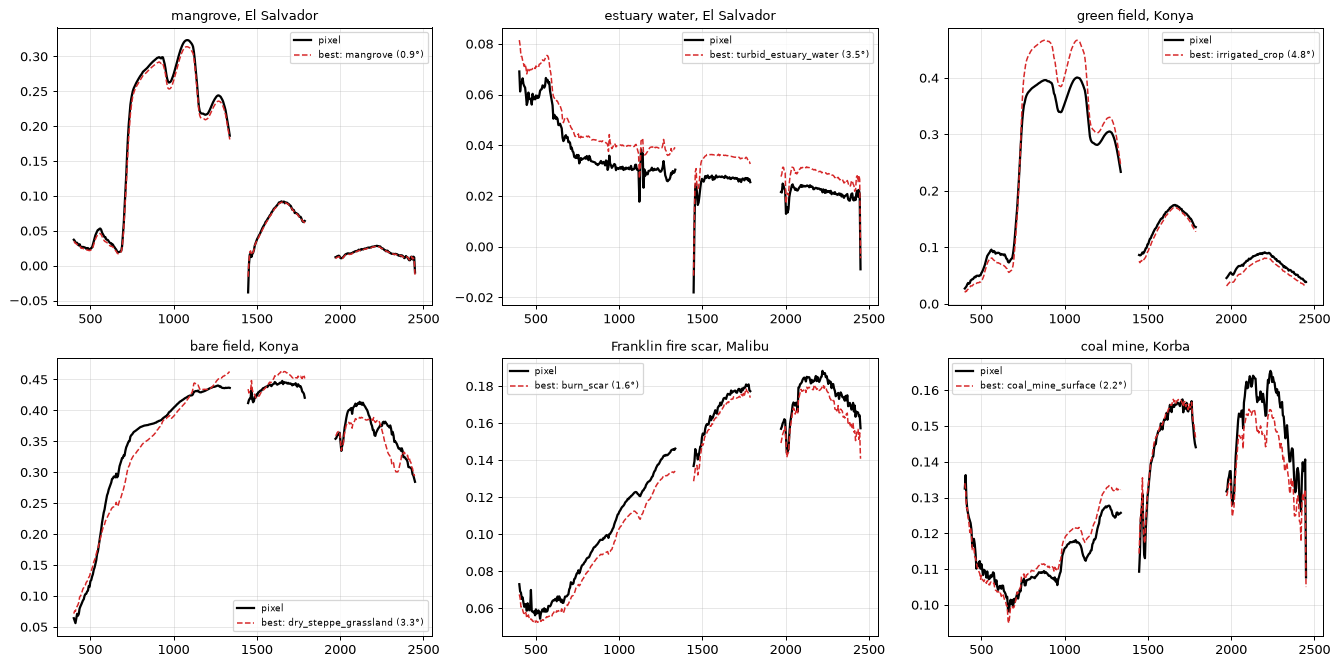

,point,best_match,angle_deg,second,angle2_deg
0,"mangrove, El Salvador",mangrove,0.9,irrigated_crop,7.1
1,"estuary water, El Salvador",turbid_estuary_water,3.5,river_water,9.1
2,"green field, Konya",irrigated_crop,4.8,sugarcane_cropland,7.5
3,"bare field, Konya",dry_steppe_grassland,3.3,dry_bare_soil,3.5
4,"Franklin fire scar, Malibu",burn_scar,1.6,bright_industrial_roof,9.1
5,"coal mine, Korba",coal_mine_surface,2.2,bright_industrial_roof,5.2


In [11]:
POINTS = [  # (scene id, lon, lat, what we expect)
    ("20250223_165546_32_4001", -88.4652, 13.2215, "mangrove, El Salvador"),
    ("20250223_165546_32_4001", -88.3821, 13.1580, "estuary water, El Salvador"),
    ("20250608_091605_90_4001", 32.6324, 37.6313, "green field, Konya"),
    ("20250608_091605_90_4001", 32.5503, 37.5975, "bare field, Konya"),
    ("20241215_185916_33_4001", -118.6673, 34.0597, "Franklin fire scar, Malibu"),
    ("20250219_053251_31_4001", 82.6670, 22.3292, "coal mine, Korba"),
]

lib_good = L[:, good]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
results = []
for ax, (sid, lon, lat, expected) in zip(axes.flat, POINTS):
    sc = hu.get_scene(sid)
    r, c = sc.lonlat_to_rowcol(lon, lat)
    spec, w = sc.read_pixel(int(r[0]), int(c[0]), bands="all")
    spec = np.interp(wl, w, spec)                 # put the pixel on the library's wavelength grid
    ang = np.degrees(hu.spectral_angle(lib_good, spec[good]))
    order = np.argsort(ang)
    best = names[order[0]]
    results.append(dict(point=expected, best_match=best, angle_deg=ang[order[0]],
                        second=names[order[1]], angle2_deg=ang[order[1]]))
    hu.plot_spectrum(ax, wl[good], spec[good], color="k", lw=1.8, label="pixel")
    hu.plot_spectrum(ax, wl, lib[best], color="C3", lw=1.2, ls="--", label=f"best: {best} ({ang[order[0]]:.1f}°)")
    ax.set_title(expected, fontsize=10); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
pd.DataFrame(results).round(1)

Most pixels match the expected material within a few degrees. Two observations:

- The **bare field** in Konya is almost equally close to *dry steppe grassland* and *dry bare soil*. In an arid summer
  landscape, senescent vegetation and soil really do look alike. You need the cellulose/lignin features around 2100 nm
  or indices such as the Cellulose Absorption Index to separate them (notebook 13).
- A small angle does not prove *identity*. SAM returns the best candidate **among the spectra you supplied**. If the true
  material is missing from the library, you still get an answer. Always set a maximum-angle threshold and label anything
  above it "unknown".

## 7. (Optional) Laboratory spectra: the USGS Spectral Library v7

The **USGS Spectral Library Version 7** (Kokaly et al., 2017) contains thousands of laboratory and field spectra of
minerals, vegetation, soils and man-made materials. To use it:

1. Download the ASCII archive (`ASCIIdata_splib07a.zip`) from the
   [USGS Spectroscopy Lab page](https://www.usgs.gov/labs/spectroscopy-lab/usgs-spectral-library).
2. Unzip it into `data/usgs_splib07/` (keep the folder structure).
3. Re-run the cell below. It looks for kaolinite, calcite and gypsum spectra, convolves them to Tanager's bands and
   plots them against our image-derived library.

If the files are missing, the cell prints a message and moves on.

In [12]:
usgs_dir = hu.DATA_DIR / "usgs_splib07"
wave_files = sorted(usgs_dir.rglob("splib07a_Wavelengths_BECK_Beckman_0.2-3.0_microns.txt")) if usgs_dir.exists() else []

if not wave_files:
    print("USGS splib07 not found in", usgs_dir, "— skipping this optional section.")
else:
    wave_file = wave_files[0]
    wanted = {"Kaolinite": "mine_spoil_bright", "Calcite": "sabkha_salt_flat", "Gypsum": "sabkha_salt_flat"}
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for mineral, compare_to in wanted.items():
        hits = sorted(usgs_dir.rglob(f"splib07a_{mineral}_*BECKb_AREF.txt"))
        if not hits:
            print("no file for", mineral); continue
        wl_u, s_u = hu.load_usgs_ascii(hits[0], wave_file)
        s_t = hu.resample_to_sensor(wl_u, s_u, scene.wavelengths, scene.fwhm)   # lab → Tanager bands
        keep = scene.good_bands & (scene.wavelengths > 2000)
        ax.plot(scene.wavelengths[keep], hu.continuum_removed(scene.wavelengths[keep], s_t[keep]),
                lw=1.5, label=f"USGS {mineral} ({hits[0].stem.split('_')[2]})")
    for n in ["mine_spoil_bright", "sabkha_salt_flat"]:
        m = (wl > 2000) & np.isfinite(lib[n])
        ax.plot(wl[m], hu.continuum_removed(wl[m], lib[n][m]), "k--" if n == "mine_spoil_bright" else "k:",
                label=f"Tanager library: {n}")
    ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("continuum removed"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.show()

USGS splib07 not found in /home/course/hyperspectral_course_notebooks/data/usgs_splib07 — skipping this optional section.


## 8. From features to applications: hyperspectral use cases in this course

| Spectral feature (nm) | What it tells you | Course theme |
|---|---|---|
| Red edge position and shape (690–750), chlorophyll dip (680) | chlorophyll content, nitrogen status, early stress | **01** Precision agriculture, **05** Ecosystem health |
| Leaf water (970, 1200), SWIR level (1500–1750) | canopy water content, irrigation deficit, drought | **01** Agriculture, **04** Climate disasters |
| Cellulose/lignin (2100, 2300) | crop residue, dry biomass, fuel load | **01** Agriculture, **04** Fire |
| NBR-type NIR/SWIR contrast, char and ash shape | burn severity, fire recovery | **04** Climate disasters |
| Al–OH (2200), carbonate (2340), iron oxides (900) | soil and mineral mapping, mine waste, construction materials | **02** Land use, mining |
| CH₄ absorption (2200–2400, fine structure) | methane plume detection | **03** Air quality & GHG |
| Green–red water-leaving signal, 700–710 nm peak | chlorophyll-a, algal blooms, turbidity | **05** Blue carbon, **06** Water quality |
| Blue–green signal of shallow water | bathymetry, seagrass and coral habitats | **05** Blue carbon |
| Material-specific roof spectra (visible colour, SWIR features) | urban materials, informal settlements, heat risk | **02** Urban & LULC |

## ✏️ Your turn

**1. Add your own library entry.** Pick a lon/lat in one of the scenes (for example the river in Ho Chi Minh City, scene
`20250407_035509_25_4001`). Average the spectra of a 3×3 window around it and find its nearest library match.
<details><summary>Hint</summary>

Use `sc.lonlat_to_rowcol(lon, lat)`, then `sc.read_cube((r-1, r+2, c-1, c+2))` and `np.nanmean(cube, axis=(1, 2))`.
Interpolate onto the library grid with `np.interp(wl, w, spectrum)` before computing angles.
</details>
<details><summary>Solution</summary>

```python
sc = hu.get_scene("20250407_035509_25_4001")
r, c = sc.lonlat_to_rowcol(106.7524, 10.7278)   # Saigon river
r, c = int(r[0]), int(c[0])
cube_small, w = sc.read_cube((r - 1, r + 2, c - 1, c + 2))
spec = np.interp(wl, w, np.nanmean(cube_small, axis=(1, 2)))
ang = np.degrees(hu.spectral_angle(L[:, good], spec[good]))
for i in np.argsort(ang)[:3]:
    print(f"{names[i]:25s} {ang[i]:.1f}°")
```
</details>

**2. Red-edge position (REP).** For every vegetation entry, find the wavelength of the maximum first derivative between
680 and 750 nm. Which vegetation type has the most "blue-shifted" (shortest-wavelength) red edge, and what could that mean?
<details><summary>Hint</summary>

`d = np.gradient(spectrum, wl)`; restrict to `(wl > 680) & (wl < 750)` and take `wl[np.argmax(d)]`. A shift towards
shorter wavelengths usually indicates lower chlorophyll content or stress.
</details>
<details><summary>Solution</summary>

```python
m = (wl > 680) & (wl < 750)
for n in GROUPS["Vegetation"]:
    d = np.gradient(lib[n][m], wl[m])
    print(f"{n:22s} REP = {wl[m][np.argmax(d)]:.0f} nm")
```
</details>

**3. Landsat instead of Sentinel-2.** Repeat the separability comparison of section 5.1 with `hu.LANDSAT8_BANDS`. Which
pairs lose most of their angle? Why is Landsat worse than Sentinel-2 for vegetation?
<details><summary>Solution</summary>

```python
l8 = np.array(list(hu.LANDSAT8_BANDS.values()))
A_l8 = sam_matrix(hu.resample_to_sensor(wl, L, l8[:, 0], l8[:, 1]))
for a, b in pairs:
    i, j = names.index(a), names.index(b)
    print(f"{a} vs {b}: Tanager {A_tan[i, j]:.1f}°, S2 {A_s2[i, j]:.1f}°, Landsat {A_l8[i, j]:.1f}°")
# Landsat has no red-edge bands, so vegetation types collapse onto similar vectors.
```
</details>

**4. Mixtures fool the library.** Build a synthetic 50/50 mixture of `burn_scar` and `chaparral_unburned`. Which library
entry is its nearest SAM match? What does this mean for mapping burn severity at 30 m?
<details><summary>Solution</summary>

```python
mix = 0.5 * lib["burn_scar"] + 0.5 * lib["chaparral_unburned"]
ang = np.degrees(hu.spectral_angle(L[:, good], mix[good]))
print([(names[i], round(ang[i], 1)) for i in np.argsort(ang)[:3]])
# A partially burned pixel can match a completely different material (e.g. dry grass or soil).
# Fractional (unmixing) approaches describe severity better than hard classes.
```
</details>

**5. Brightness vs shape.** Multiply the mangrove spectrum by 0.5, as if it were in shadow. What happens to its spectral
angle with the original? And to the Euclidean distance? Which measure would you use across hilly terrain?
<details><summary>Solution</summary>

```python
a, b = lib["mangrove"][good], 0.5 * lib["mangrove"][good]
print("angle:", np.degrees(hu.spectral_angle(a[None], b))[0], "deg")
print("Euclidean distance:", np.linalg.norm(a - b))
# The angle is 0: SAM ignores brightness. The Euclidean distance is large.
```
</details>

## Key takeaways

- A spectral signature is shaped by electronic absorption (VIS–NIR), vibrational absorption (SWIR) and scattering.
  Diagnostic information sits in **narrow features** at known positions.
- Continuum removal and band depth make features comparable between bright and dark targets.
- Know your sensor: band centres, FWHM, sampling, GSD and SNR all limit what you can detect. Tanager's SNR is excellent
  on land but low in the SWIR over water and in the atmospheric windows.
- Resampling to Sentinel-2 shrinks the spectral angle between similar materials. Hyperspectral pays off for **subtle**
  differences.
- SAM matches pixel shape to library shape, ignoring brightness, but it can only choose among the materials you provide.

**For your project:** decide which spectral features carry the information your use case needs. If the key features
sit in wide Sentinel-2 bands or between them, you have a strong argument for hyperspectral data. Start building a small
library of your own target materials now; you will need it for target detection (notebook 14) and classification (notebook 15).

**References**: Clark & Roush (1984) *J. Geophys. Res.* 89; Kruse et al. (1993) *Remote Sens. Environ.* 44;
Kokaly et al. (2017) USGS Data Series 1035; Curran (1989) *Remote Sens. Environ.* 30 (foliar biochemistry).

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · ESA WorldCover 2021 v200 — CC-BY 4.0 (library pixel selection)